<a href="https://colab.research.google.com/github/m270324-sudo/ME315A/blob/main/Lab09_Pastene.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install plotnine
import polars as pl

In [2]:
# 1. Importe o conjunto de dados diamonds, cujo arquivo está disponível no website da disciplina.

diamonds = pl.read_csv("diamonds.csv.gz")

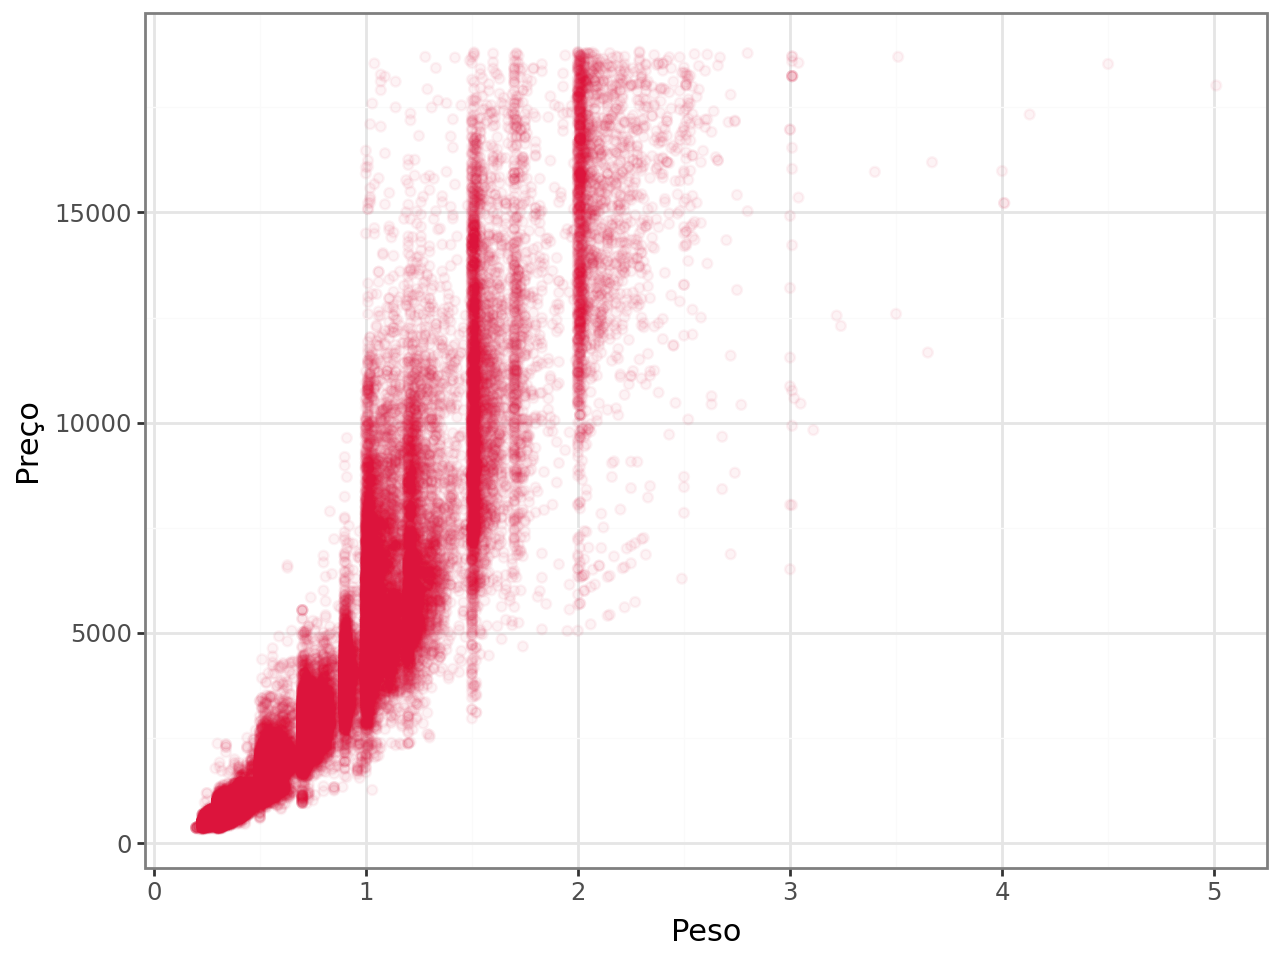

In [3]:
# 2. Crie uma visualização de dados que descreva a associação existente entre as variáveis peso (carat) e preço (price). Que ações você tomou para garantir que você produziu um gráfico de boa qualidade? Escreva um parágrafo comunicando os seus achados.

from plotnine import ggplot, aes, geom_point, labs, theme_bw
plot01 = (
    ggplot(diamonds)
    + aes (x = 'carat', y = 'price')
    + geom_point(alpha=0.05, color = 'crimson')
    + labs(x = 'Peso', y = 'Preço')
    + theme_bw()
)
plot01

Como diamonds possui muitas observações, foi necessário tomar medidas para contornar o problema dos pontos se sobrepontos e se tornando uma única densidade indistingível (overplotting). Apliquei no gráfico de dispersão opacidade de 5% aos pontos para que ficasse possível a visualização das regiões onde a frequência é mais alta. Ademais, é percepitível uma relação positiva entre preço e peso, relação forte até aproximadamente 2,5 quilates, uma vezque após esse ponto parece não ter aumento significativo no preço mesmo com o aumento do peso.

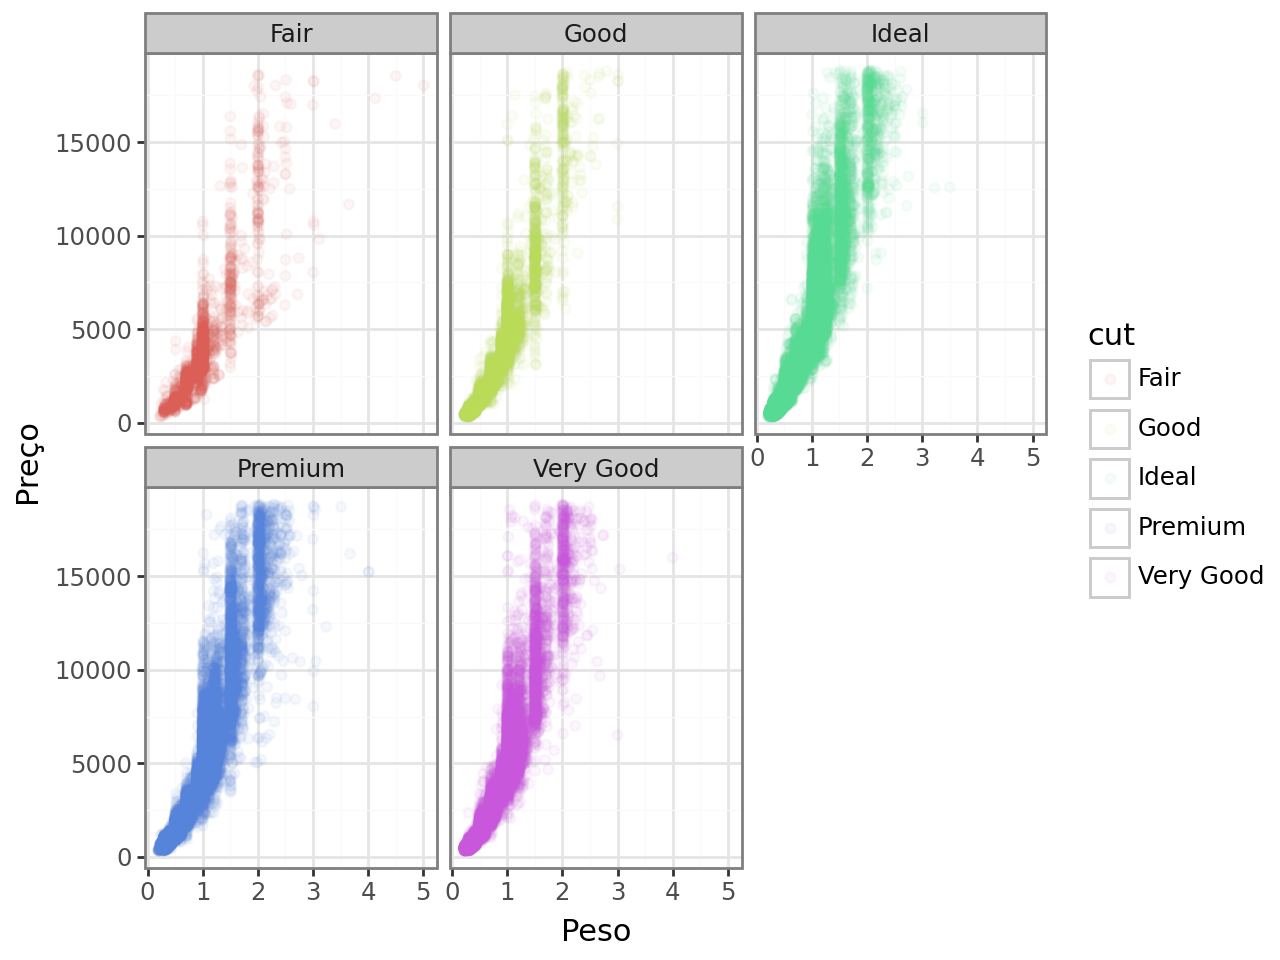

In [4]:
# 3. A relação identificada na questão anterior é a mesma relação presente nos diferentes cortes de diamantes? Crie uma visualização que demonstre seus achados eficientemente. Descreva sua conclusão em um parágrafo.

import numpy as np


from plotnine import ggplot, aes, geom_point, facet_wrap , labs, theme_bw
plot02 = (
    ggplot(diamonds)
    + aes (x = 'carat', y = 'price', color = 'cut')
    + geom_point(alpha = 0.05)
    + facet_wrap('cut')
    + labs(x = 'Peso', y = 'Preço')
    + theme_bw()
)

plot02


A relação se mantém, com a qualidade de corte mais baixa **('Fair')** apareçendo concentrada em dimantes de menor peso e preço, enquanto a qualidade de corte mais alta **('Ideal')** apareçe concentrada seguindo a relação peso e preço, ficando concentrada no intervalo antes dos 2,5 quilates onde a realção preço e peso enfraquece

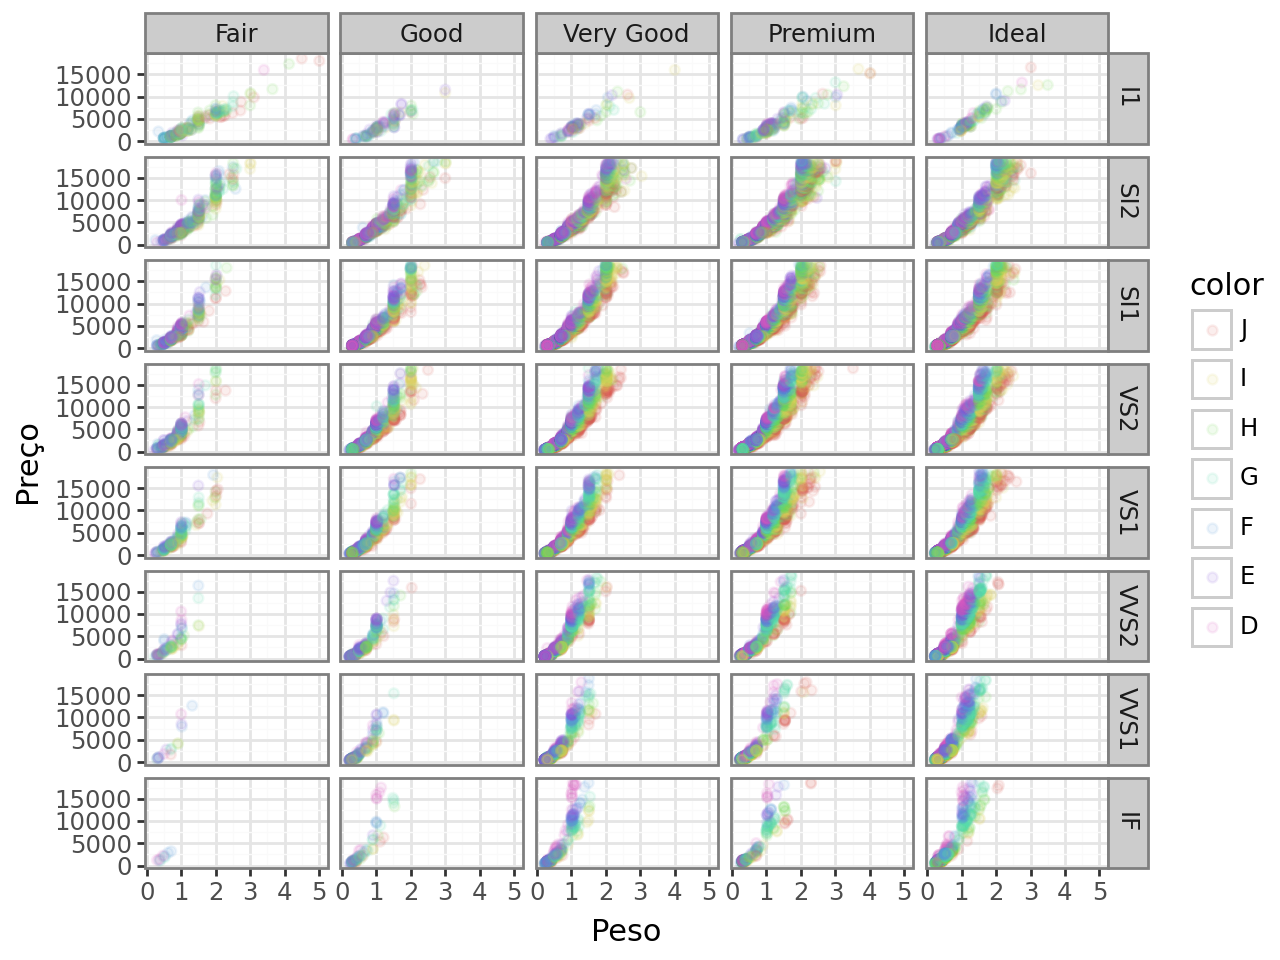

In [12]:
# 4. Crie uma visualização que mostre a relação entre preço e peso do diamante, considerando as diferentes combinações de qualidade de corte, cor e clareza do diamante. Quais foram as dificuldades encontradas? A relação entre preço e peso é a mesma para diferentes configurações de diamantes?


ord_cut = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
ord_color = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
ord_clarity = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']


ord_diamonds = diamonds.with_columns([
    pl.col('cut').cast(pl.Enum(ord_cut)),
    pl.col('color').cast(pl.Enum(ord_color)),
    pl.col('clarity').cast(pl.Enum(ord_clarity))
])


from plotnine import ggplot, aes, geom_point, facet_grid
plot03 = (
  ggplot(ord_diamonds) + aes(x = 'carat', y = 'price', color = 'color')
  + geom_point(alpha = 0.1)
  + facet_grid("clarity", "cut")
  + labs(x = "Peso", y = "Preço")
  + theme_bw()
)

plot03




As maiores dificuldades encontradas são trabalhar com múltiplas variáveis. A relação se mantem num parâmetro geral apesar de pontos diferentes como em quando a claridade está em seu nível mais alto